# Imports

In [1]:
import numpyro
numpyro.set_host_device_count(8)

import jax
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print("local device count:", jax.local_device_count())
print("local devices:")
for d in jax.local_devices():
    print("  ", d)
    
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_log_sed
)

from data import(
    prepare_burst
)

from run import(
    set_priors,
    run_fit,
    posthoc_samples
)

from results import(
    save_run
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import arviz as az

az.rcParams["plot.max_subplots"] = 200

import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.1
local device count: 8
local devices:
   cpu:0
   cpu:1
   cpu:2
   cpu:3
   cpu:4
   cpu:5
   cpu:6
   cpu:7


In [2]:
# import sys
# print(sys.executable)  # Should point to your venv path, not /mnt/sw/nix/...

In [3]:
# import tqdm.std

# # Force tqdm to use newlines and flush output instantly for Jupyter
# def line_printer(file):
#     def print_status(s):
#         file.write(s.replace("\r", "") + "\n")
#         file.flush()
#     return print_status

# tqdm.std.status_printer = line_printer

In [4]:
# import sys
# import tqdm.std

# class ThreadSafeStdOut:
#     def __init__(self, stream):
#         self.stream = stream
#     def write(self, s):
#         self.stream.write(s)
#         self.stream.flush()
#     def flush(self):
#         self.stream.flush()

# # Override tqdm's default output file handle
# tqdm.std.tqdm.stqdm_file = ThreadSafeStdOut(sys.stdout)

# Run

In [5]:
from pathlib import Path

PROJECT  = Path("/mnt/home/hsiegel/FRBayes")
event_id = "22310619_BB"

data_path = PROJECT / "data" / f"event_{event_id}.npz"
out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

n_pulses = 4
num_chains = 8
target_accept_prob = 0.8
repulsion_dict = {"x_min":3, "snr_on":1}

priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0)
# priors = set_priors(burst, single_pulse_fn, s_opt=100.0, gamma_range=(-10.0, 30.0),beta_range=(-10.0, 30.0))

mcmc   = run_fit(burst, single_pulse_fn, priors, FD_gaussianlikelihood, 
                 num_chains=num_chains, n_pulses=n_pulses, target_accept_prob=target_accept_prob,
                ordered_times=False, repulsion=repulsion_dict)#, num_warmup = 200, num_samples = 200)
samples = mcmc.get_samples()
# extra = mcmc.get_extra_fields()
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})
# extra  = posthoc_samples(mcmc, burst, single_pulse_fn, priors)
# idata  = save_run(None, mcmc, burst, priors, data_path,
#                   single_pulse_fn=single_pulse_fn, extra_samples=extra, event_id=event_id)

806 good channels -> 50 blocks of 16 (6 dropped); block span median 6.641 MHz, max 37.109 MHz
noise estimated from 171 of 858 time bins (first 20% of the segment)
Fourier truncation: keeping 52 of 430 bins (up to 5.9 kHz of 48.8 kHz)
weighted mean frequency 592.4 MHz, reference frequency 563.1 MHz
prior being set with bounds:
sigma_min = 2.6890819453714833e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011637152739660515
prior being set with bounds:
c1_min = -1.9209625 
c1_max = 38.41925 
c2_min = -5.0385747 
c2_max = 0.25192875
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: Uniform(low=2.68908e-05, high=0.00036608)
tau_ref: Uniform(low=0, high=0.00116372)
c1: Uniform(low=-1.92096, high=38.4193)
c2: Uniform(low=-5.03857, high=0.251929)
A_snr: HalfNormal(scale=100)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling th

Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]

  0%|          | 0/1200 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]


  0%|          | 0/1200 [00:00<?, ?it/s]


Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]



  0%|          | 0/1200 [00:00<?, ?it/s]



Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]




  0%|          | 0/1200 [00:00<?, ?it/s]




Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]





  0%|          | 0/1200 [00:00<?, ?it/s]





Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]






  0%|          | 0/1200 [00:00<?, ?it/s]






Compiling.. :   0%|          | 0/1200 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


Running chain 1:   0%|          | 0/1200 [00:05<?, ?it/s]

Running chain 2:   0%|          | 0/1200 [00:05<?, ?it/s]


Running chain 3:   0%|          | 0/1200 [00:05<?, ?it/s]



Running chain 4:   0%|          | 0/1200 [00:05<?, ?it/s]




Running chain 5:   0%|          | 0/1200 [00:05<?, ?it/s]





Running chain 6:   0%|          | 0/1200 [00:05<?, ?it/s]






Running chain 1:   5%|▌         | 60/1200 [00:32<08:45,  2.17it/s]

Running chain 0:   5%|▌         | 60/1200 [00:35<09:32,  1.99it/s]


Running chain 3:   5%|▌         | 60/1200 [00:35<09:36,  1.98it/s]





Running chain 6:   5%|▌         | 60/1200 [00:40<11:10,  1.70it/s]






Running chain 7:   5%|▌         | 60/1200 [00:40<11:15,  1.69it/s]



Running chain 4:   5%|▌         | 60/1200 [00:44<12:31,  1.52it/s]




Running chain 0:  10%|█         | 120/1200 [01:19<11:30,  1.56it/s][A






Running chain 0:  25%|██▌       | 300/1200 [01:30<02:38,  5.70it/s]






Running chain 0:  30%|███       | 360/1200 [01:33<01:49,  

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [6]:
int(mcmc.get_extra_fields()["diverging"].sum())

30

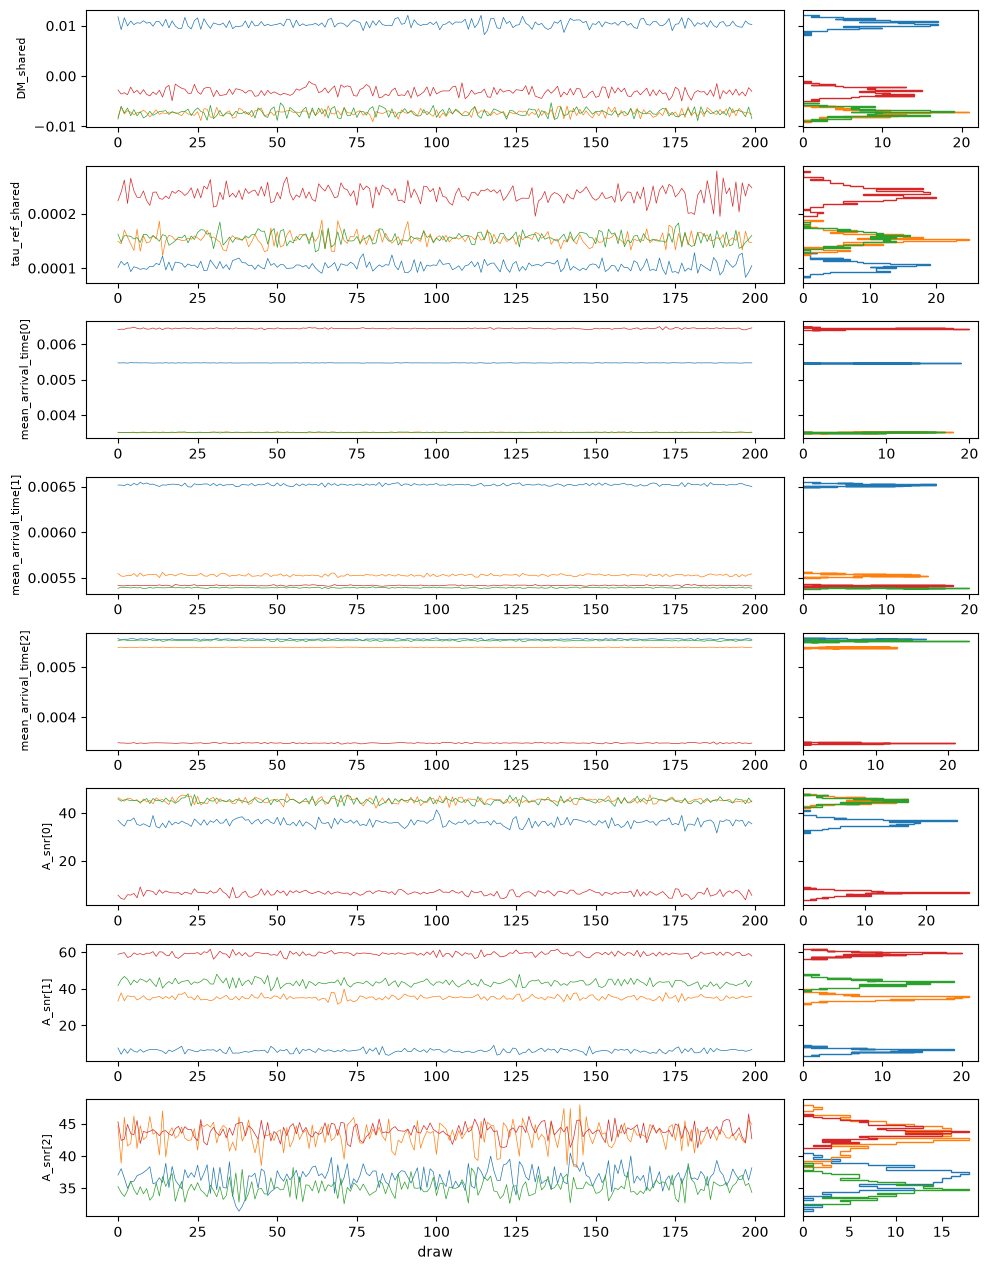

In [7]:
import numpy as np
import matplotlib.pyplot as plt

names = ["DM_shared", "tau_ref_shared", "mean_arrival_time", "A_snr"]     # the few you want

s = mcmc.get_samples(group_by_chain=True)                                    # each (chain, draw, ...)
div = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"])    # (chain, draw)

# One row per scalar: per-pulse sites are split into [0], [1], ...
rows = []
for k in names:
    v = np.asarray(s[k])
    if v.ndim == 2:
        rows.append((k, v))
    else:
        rows += [(f"{k}[{j}]", v[:, :, j]) for j in range(v.shape[2])]

fig, axes = plt.subplots(len(rows), 2, figsize=(10, 1.6 * len(rows)), squeeze=False,
                         sharey="row", gridspec_kw={"width_ratios": [4, 1]})
for (label, v), (ax_t, ax_h) in zip(rows, axes):
    for c in range(v.shape[0]):
        line, = ax_t.plot(v[c], lw=0.5)
        ax_t.plot(np.flatnonzero(div[c]), v[c][div[c]], "|", color="red", ms=10)   # divergent draws
        ax_h.hist(v[c], bins=30, histtype="step", orientation="horizontal", color=line.get_color())
    ax_t.set_ylabel(label, fontsize=8)
axes[-1, 0].set_xlabel("draw")
plt.tight_layout()
plt.show()

806 good channels -> 806 blocks of 1 (0 dropped); block span median 0.000 MHz, max 0.000 MHz
noise estimated from 171 of 858 time bins (first 20% of the segment)
Fourier truncation: keeping 429 of 430 bins (up to 48.8 kHz of 48.8 kHz)
weighted mean frequency 584.6 MHz, reference frequency 554.0 MHz
prior being set with bounds:
sigma_min = 3.2594932345220168e-06 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0012035367386106551
prior being set with bounds:
c1_min = -3.2299006 
c1_max = 37.902573 
c2_min = -6.7748923 
c2_max = 0.33874464
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.228245, high=0.228245)
sigma: Uniform(low=3.25949e-06, high=0.00036608)
tau_ref: Uniform(low=0, high=0.00120354)
c1: Uniform(low=-3.2299, high=37.9026)
c2: Uniform(low=-6.77489, high=0.338745)
A_snr: HalfNormal(scale=100)
sampling the amplitude as A_snr (SNR units)
starting values:
  mean_arrival_time  [0.0034045 0.0040635 0.0047224 0.0053814]
  sigma           

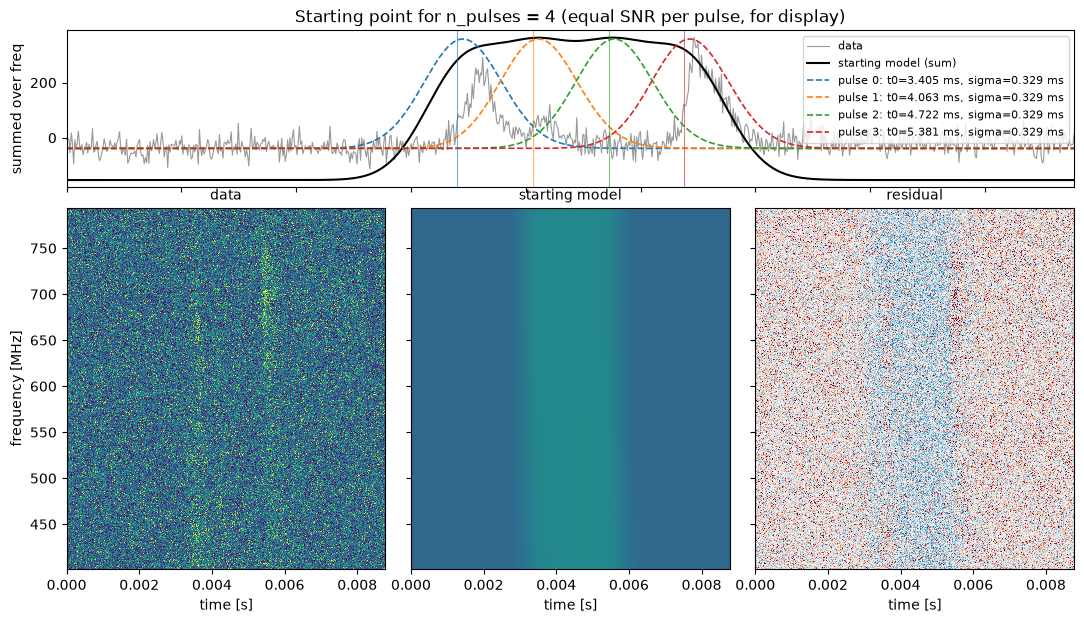

In [13]:
# -------------------------------------------------------------------
# Plot the sampler's starting pulses against the data
# -------------------------------------------------------------------
# Uses `burst`, `priors` and `single_pulse_fn` from the cells above. Nothing is sampled: the
# model is traced once with the starting values that run_fit would use, and the resulting
# pulses are drawn over the data.
#
# The starting amplitudes are random draws, so for display each pulse is instead scaled by the
# least-squares amplitude that best matches the data given its shape (clipped at zero). That
# puts the pulses on the data's scale; it does not change where they start.
#
# Both data and model are shown on the retained Fourier bins only, i.e. low-passed exactly as
# the likelihood sees them.

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpyro.distributions as dist
from numpyro import handlers

from run import default_init
from likelihood import FD_gaussianlikelihood, matched_filter_and_gram
from pathlib import Path


# PROJECT  = Path("/arc/home/hsiegel/FRBayes")
PROJECT  = Path("/mnt/home/hsiegel/FRBayes")
# event_id = "22154974_BB"
event_id = "22310619_BB"

data_path = PROJECT / "data" / f"event_{event_id}.npz"
out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

burst = prepare_burst(
    path=data_path,
    n_avg=1,                # frequency channels averaged per block
    fd_downsample=1,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

n_pulses = 4

priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0)
# ---- 1. Starting values, read off one trace of the model ----
# The starting point is the same for every likelihood, so the unmarginalized one is traced
# here; it needs an amplitude prior, which is added for this trace only if absent.
init = default_init(burst, priors, n_pulses)
trace_priors = dict(priors)
if not ({"A", "A_snr"} & trace_priors.keys()):
    trace_priors["A_snr"] = dist.HalfNormal(100.0)
 
model = handlers.substitute(handlers.seed(FD_gaussianlikelihood, 0), substitute_fn=init)
trace = handlers.trace(model).get_trace(
    data_fd=burst.data_fd,
    sigma_noise_fd=burst.sigma_noise_fd,
    n_pulses=n_pulses,
    shared_params = ("DM","tau_ref"),
    priors=trace_priors,
    single_pulse_fn=single_pulse_fn,
    spectral_coeff_map=burst.spectral_coeff_map if "c1" in priors else None,
)
 
shape_names = [k for k in ("mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2",
                           "gamma", "beta", "delta") if k in trace]
start = {k: jnp.asarray(trace[k]["value"]).reshape(n_pulses) for k in shape_names}
 
print("starting values:")
for k, v in start.items():
    print(f"  {k:18s} {np.round(np.asarray(v), 7)}")
 
# ---- 2. Templates, all scaled to the same signal-to-noise ----
# Every pulse gets the same optimal SNR, so each one is visible however it overlaps the data or
# its neighbours. (A least-squares fit to the data is NOT used here: overlapping starting
# templates trade amplitude, and several come out negative and vanish from the plot.)
templates = jax.vmap(single_pulse_fn)(start)                     # (P, nfreq, nfourier), unit fluence
inv_noise_var = 1.0 / jnp.broadcast_to(jnp.asarray(burst.sigma_noise_fd), burst.data_fd.shape) ** 2
rho, gram = matched_filter_and_gram(templates, burst.data_fd, inv_noise_var)
snr_opt = jnp.sqrt(jnp.diag(gram))
A_display = 1.0 / snr_opt                                        # unit SNR each; rescaled to the data below
 
# ---- 3. Back to the time domain, on the retained Fourier bins ----
# Each retained bin goes back to its own index on the full rfft grid before inverting, so the
# truncation and the dropped DC bin are respected.
n_full = burst.n_time // 2 + 1
df = 1.0 / (burst.n_time * burst.dt)
bin_index = np.rint(np.asarray(burst.fourier_freqs).reshape(-1) / df).astype(int)
 
def to_time_domain(X):
    X = np.asarray(X)
    full = np.zeros(X.shape[:-1] + (n_full,), dtype=complex)
    full[..., bin_index] = X
    return np.fft.irfft(full, n=burst.n_time, axis=-1) / burst.dt
 
data_td = to_time_domain(burst.data_fd)                                       # (nfreq, ntime)
pulses_td = to_time_domain(np.asarray(A_display)[:, None, None] * np.asarray(templates))  # (P, nfreq, ntime)
 
# One overall factor so the summed starting model peaks at the data's peak, for comparison
scale = data_td.sum(axis=0).max() / pulses_td.sum(axis=(0, 1)).max()
pulses_td = scale * pulses_td
model_td = pulses_td.sum(axis=0)
resid_td = data_td - model_td
 
times = np.asarray(burst.times).reshape(-1)
freq = np.asarray(burst.freq_channels).reshape(-1)
t0 = np.asarray(start["mean_arrival_time"])
sig = np.asarray(start["sigma"])
 
# ---- 4. Plot ----
fig = plt.figure(figsize=(13, 7))
gs = gridspec.GridSpec(2, 3, height_ratios=[1.3, 3], hspace=0.08, wspace=0.08, figure=fig)
 
ax_ts = fig.add_subplot(gs[0, :])
ax_d = fig.add_subplot(gs[1, 0])
ax_m = fig.add_subplot(gs[1, 1], sharex=ax_d, sharey=ax_d)
ax_r = fig.add_subplot(gs[1, 2], sharex=ax_d, sharey=ax_d)
 
# Top: frequency-summed time series
colors = plt.cm.tab10(np.arange(n_pulses) % 10)
ax_ts.plot(times, data_td.sum(axis=0), color="0.6", lw=0.8, label="data")
ax_ts.plot(times, model_td.sum(axis=0), color="k", lw=1.5, label="starting model (sum)")
for j in range(n_pulses):
    ax_ts.plot(times, pulses_td[j].sum(axis=0), color=colors[j], lw=1.2, ls="--",
               label=f"pulse {j}: t0={t0[j]*1e3:.3f} ms, sigma={sig[j]*1e3:.3f} ms")
    ax_ts.axvline(t0[j], color=colors[j], lw=0.8, alpha=0.6)
ax_ts.set_xlim(times[0], times[-1])
ax_ts.set_ylabel("summed over freq")
ax_ts.legend(fontsize=8, loc="upper right")
ax_ts.set_title(f"Starting point for n_pulses = {n_pulses} (equal SNR per pulse, for display)")
ax_ts.tick_params(labelbottom=False)
 
# Bottom: waterfalls
extent = (times[0], times[-1], freq[0], freq[-1])
vmin, vmax = np.percentile(data_td, [1, 99])
vres = np.percentile(np.abs(resid_td), 99)
kw = dict(aspect="auto", origin="lower", interpolation="nearest", extent=extent)
ax_d.imshow(data_td, cmap="viridis", vmin=vmin, vmax=vmax, **kw)
ax_m.imshow(model_td, cmap="viridis", vmin=vmin, vmax=vmax, **kw)
ax_r.imshow(resid_td, cmap="RdBu_r", vmin=-vres, vmax=vres, **kw)
for ax, title in ((ax_d, "data"), (ax_m, "starting model"), (ax_r, "residual")):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("time [s]")
    # for j in range(n_pulses):
    #     ax.axvline(t0[j], color=colors[j], lw=0.6, alpha=0.5)
ax_d.set_ylabel("frequency [MHz]")
ax_m.tick_params(labelleft=False)
ax_r.tick_params(labelleft=False)
 
plt.show()


In [7]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,10.214,24.800,2.387,0.000,0.000
A[1],0.000,0.000,0.000,0.000,9.732,20.976,2.668,0.000,0.000
A[2],0.000,0.000,0.000,0.000,12.477,24.029,1.808,0.000,0.000
A[3],0.000,0.000,0.000,0.000,9.760,23.012,2.657,0.000,0.000
A_snr[0],25.753,21.849,0.555,56.698,9.385,9.689,3.033,7.562,1.616
A_snr[1],32.768,20.213,6.896,59.752,9.310,9.648,3.152,6.995,2.199
A_snr[2],40.361,25.154,0.954,60.714,12.089,18.203,1.809,8.709,3.287
A_snr[3],20.460,16.803,2.049,44.805,9.780,23.258,2.640,5.812,1.874
DM[0],-0.001,0.006,-0.004,0.014,20.326,9.627,1.315,0.002,0.002
DM[1],-0.001,0.006,-0.004,0.014,20.326,9.627,1.315,0.002,0.002


In [20]:
d = 1347
for k in ["A_snr", "mean_arrival_time", "sigma", "tau_ref", "toa_separation"]:
    print(f"{k:18s}", np.round(np.asarray(samples[k][d]), 6))   # pairs order: 01, 02, 03, 12, 13, 23

A_snr              [56.577377 27.092205 20.91988  35.954857]
mean_arrival_time  [0.005472 0.003574 0.005297 0.003287]
sigma              [3.0e-05 3.1e-05 2.7e-05 5.9e-05]
tau_ref            [0.000285 0.000285 0.000285 0.000285]
toa_separation     [30.96715   3.094666 24.63173  29.487724  3.176759 23.412607]


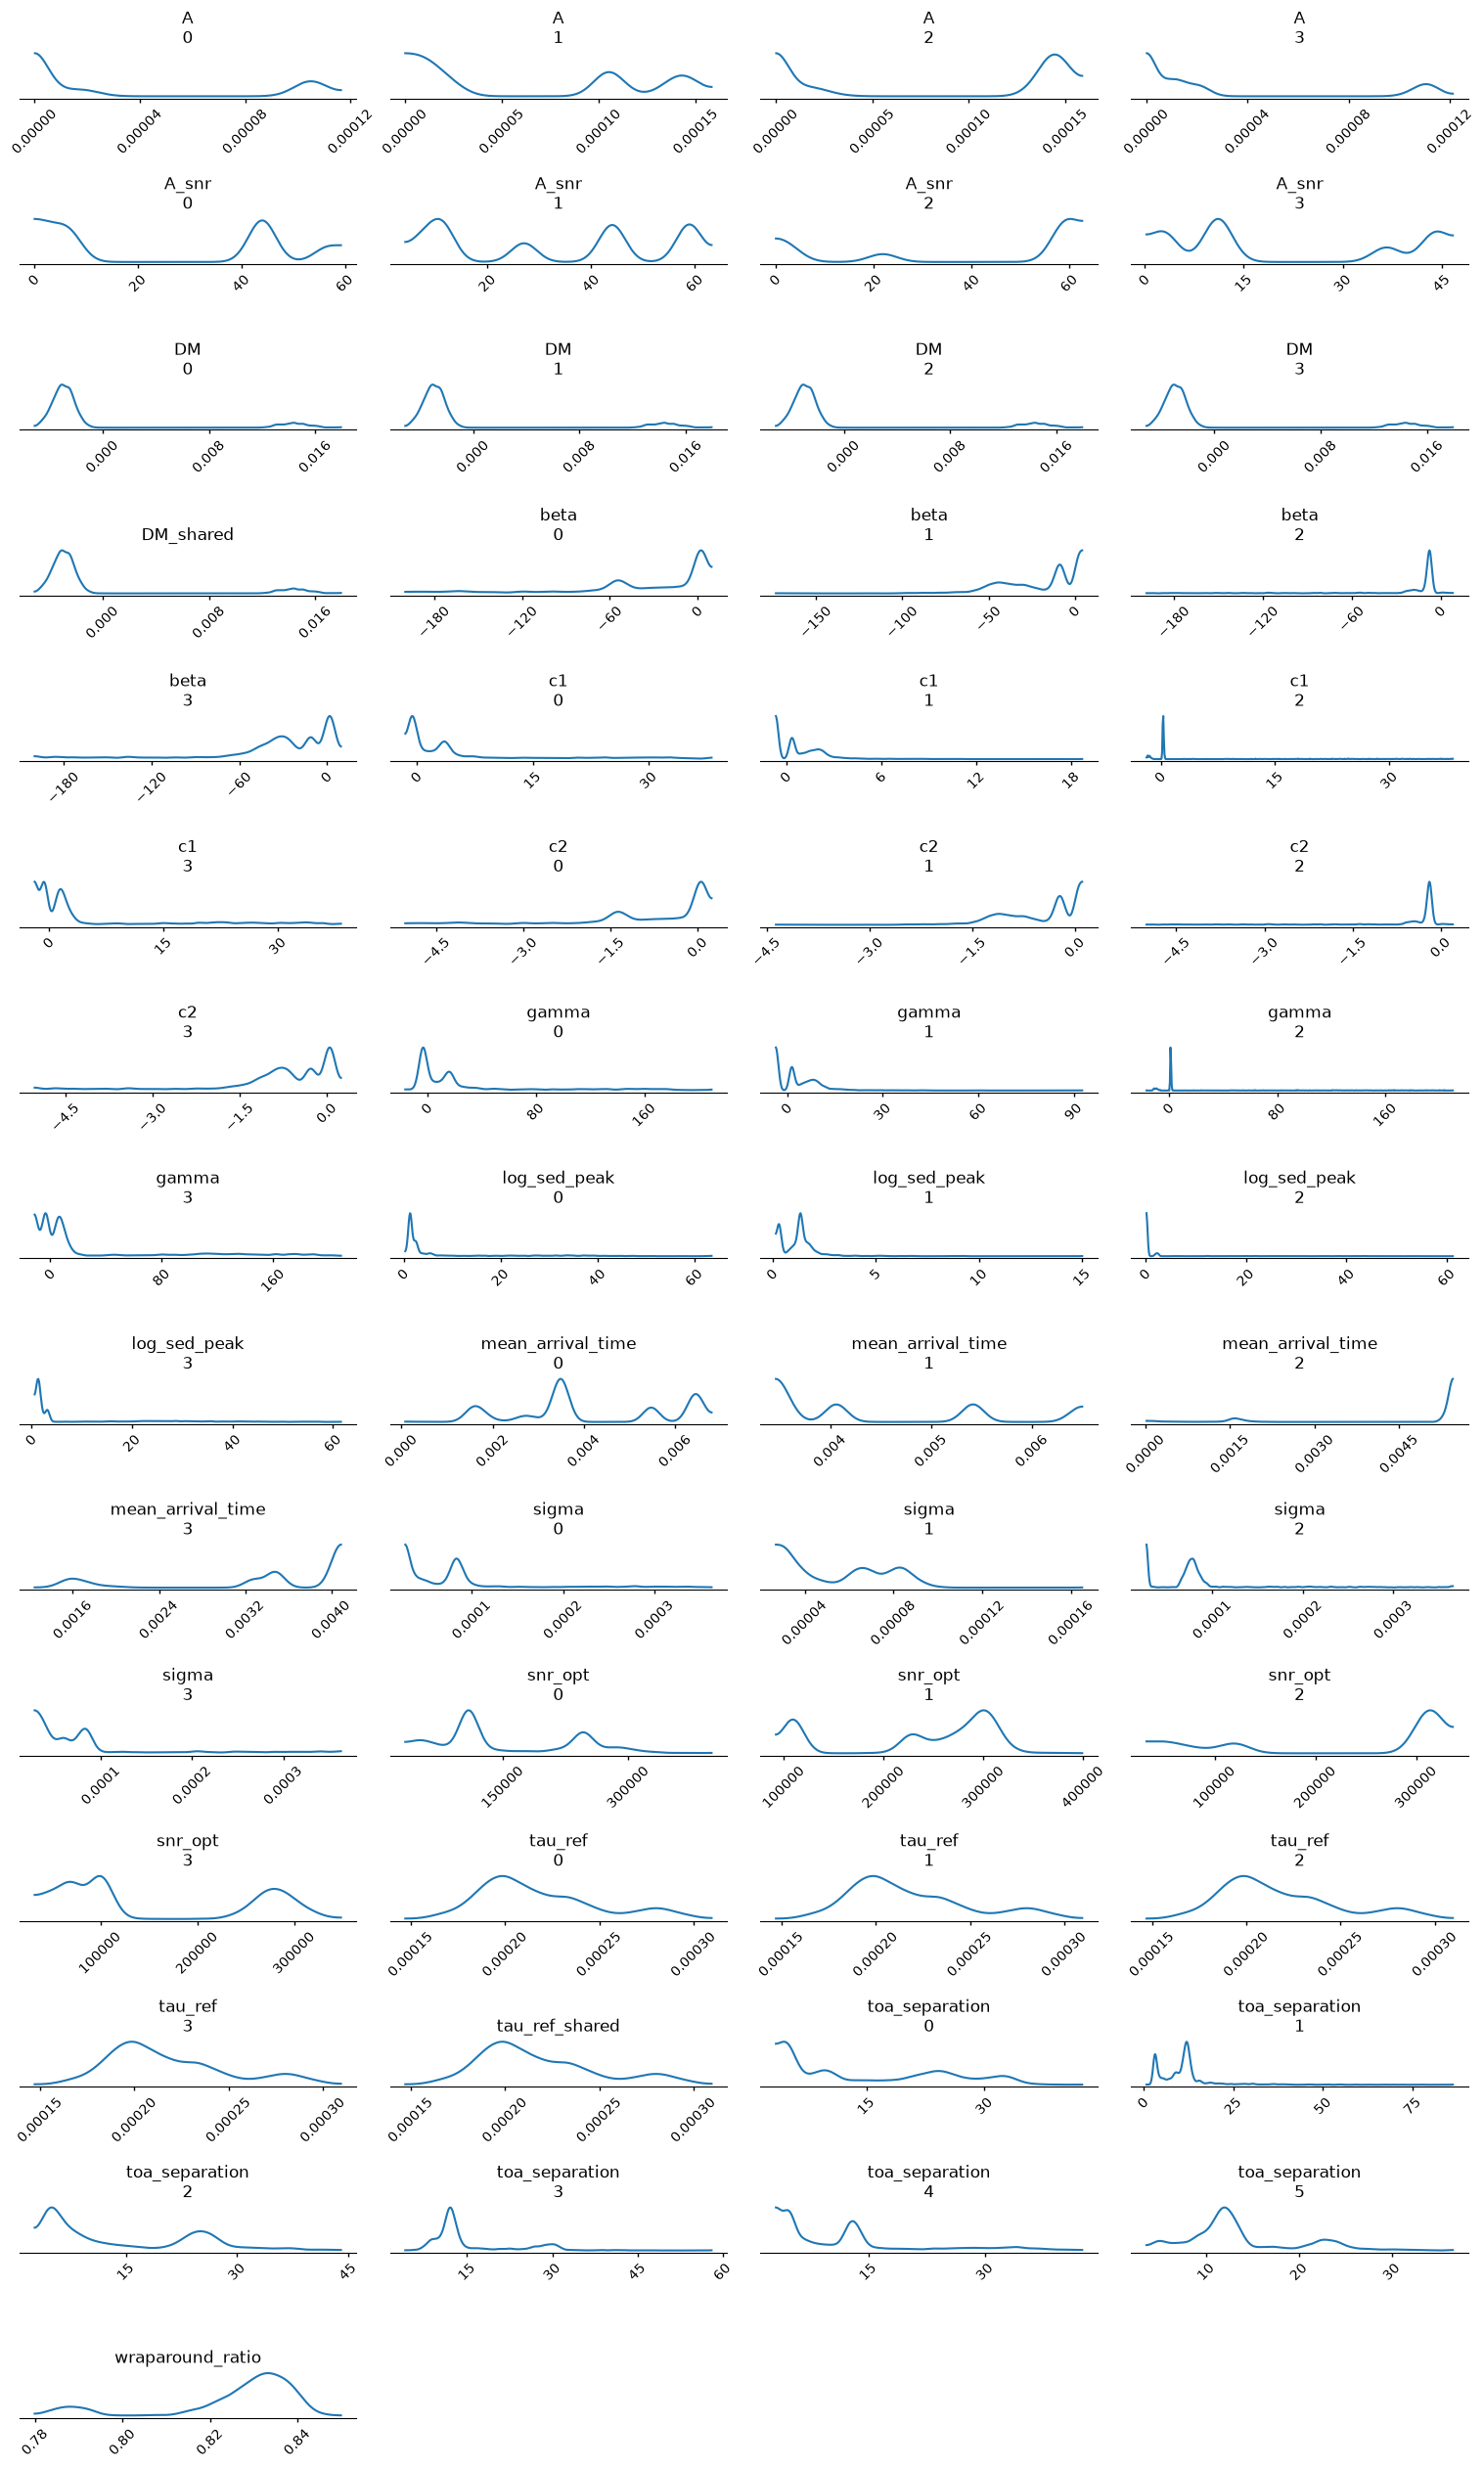

In [8]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

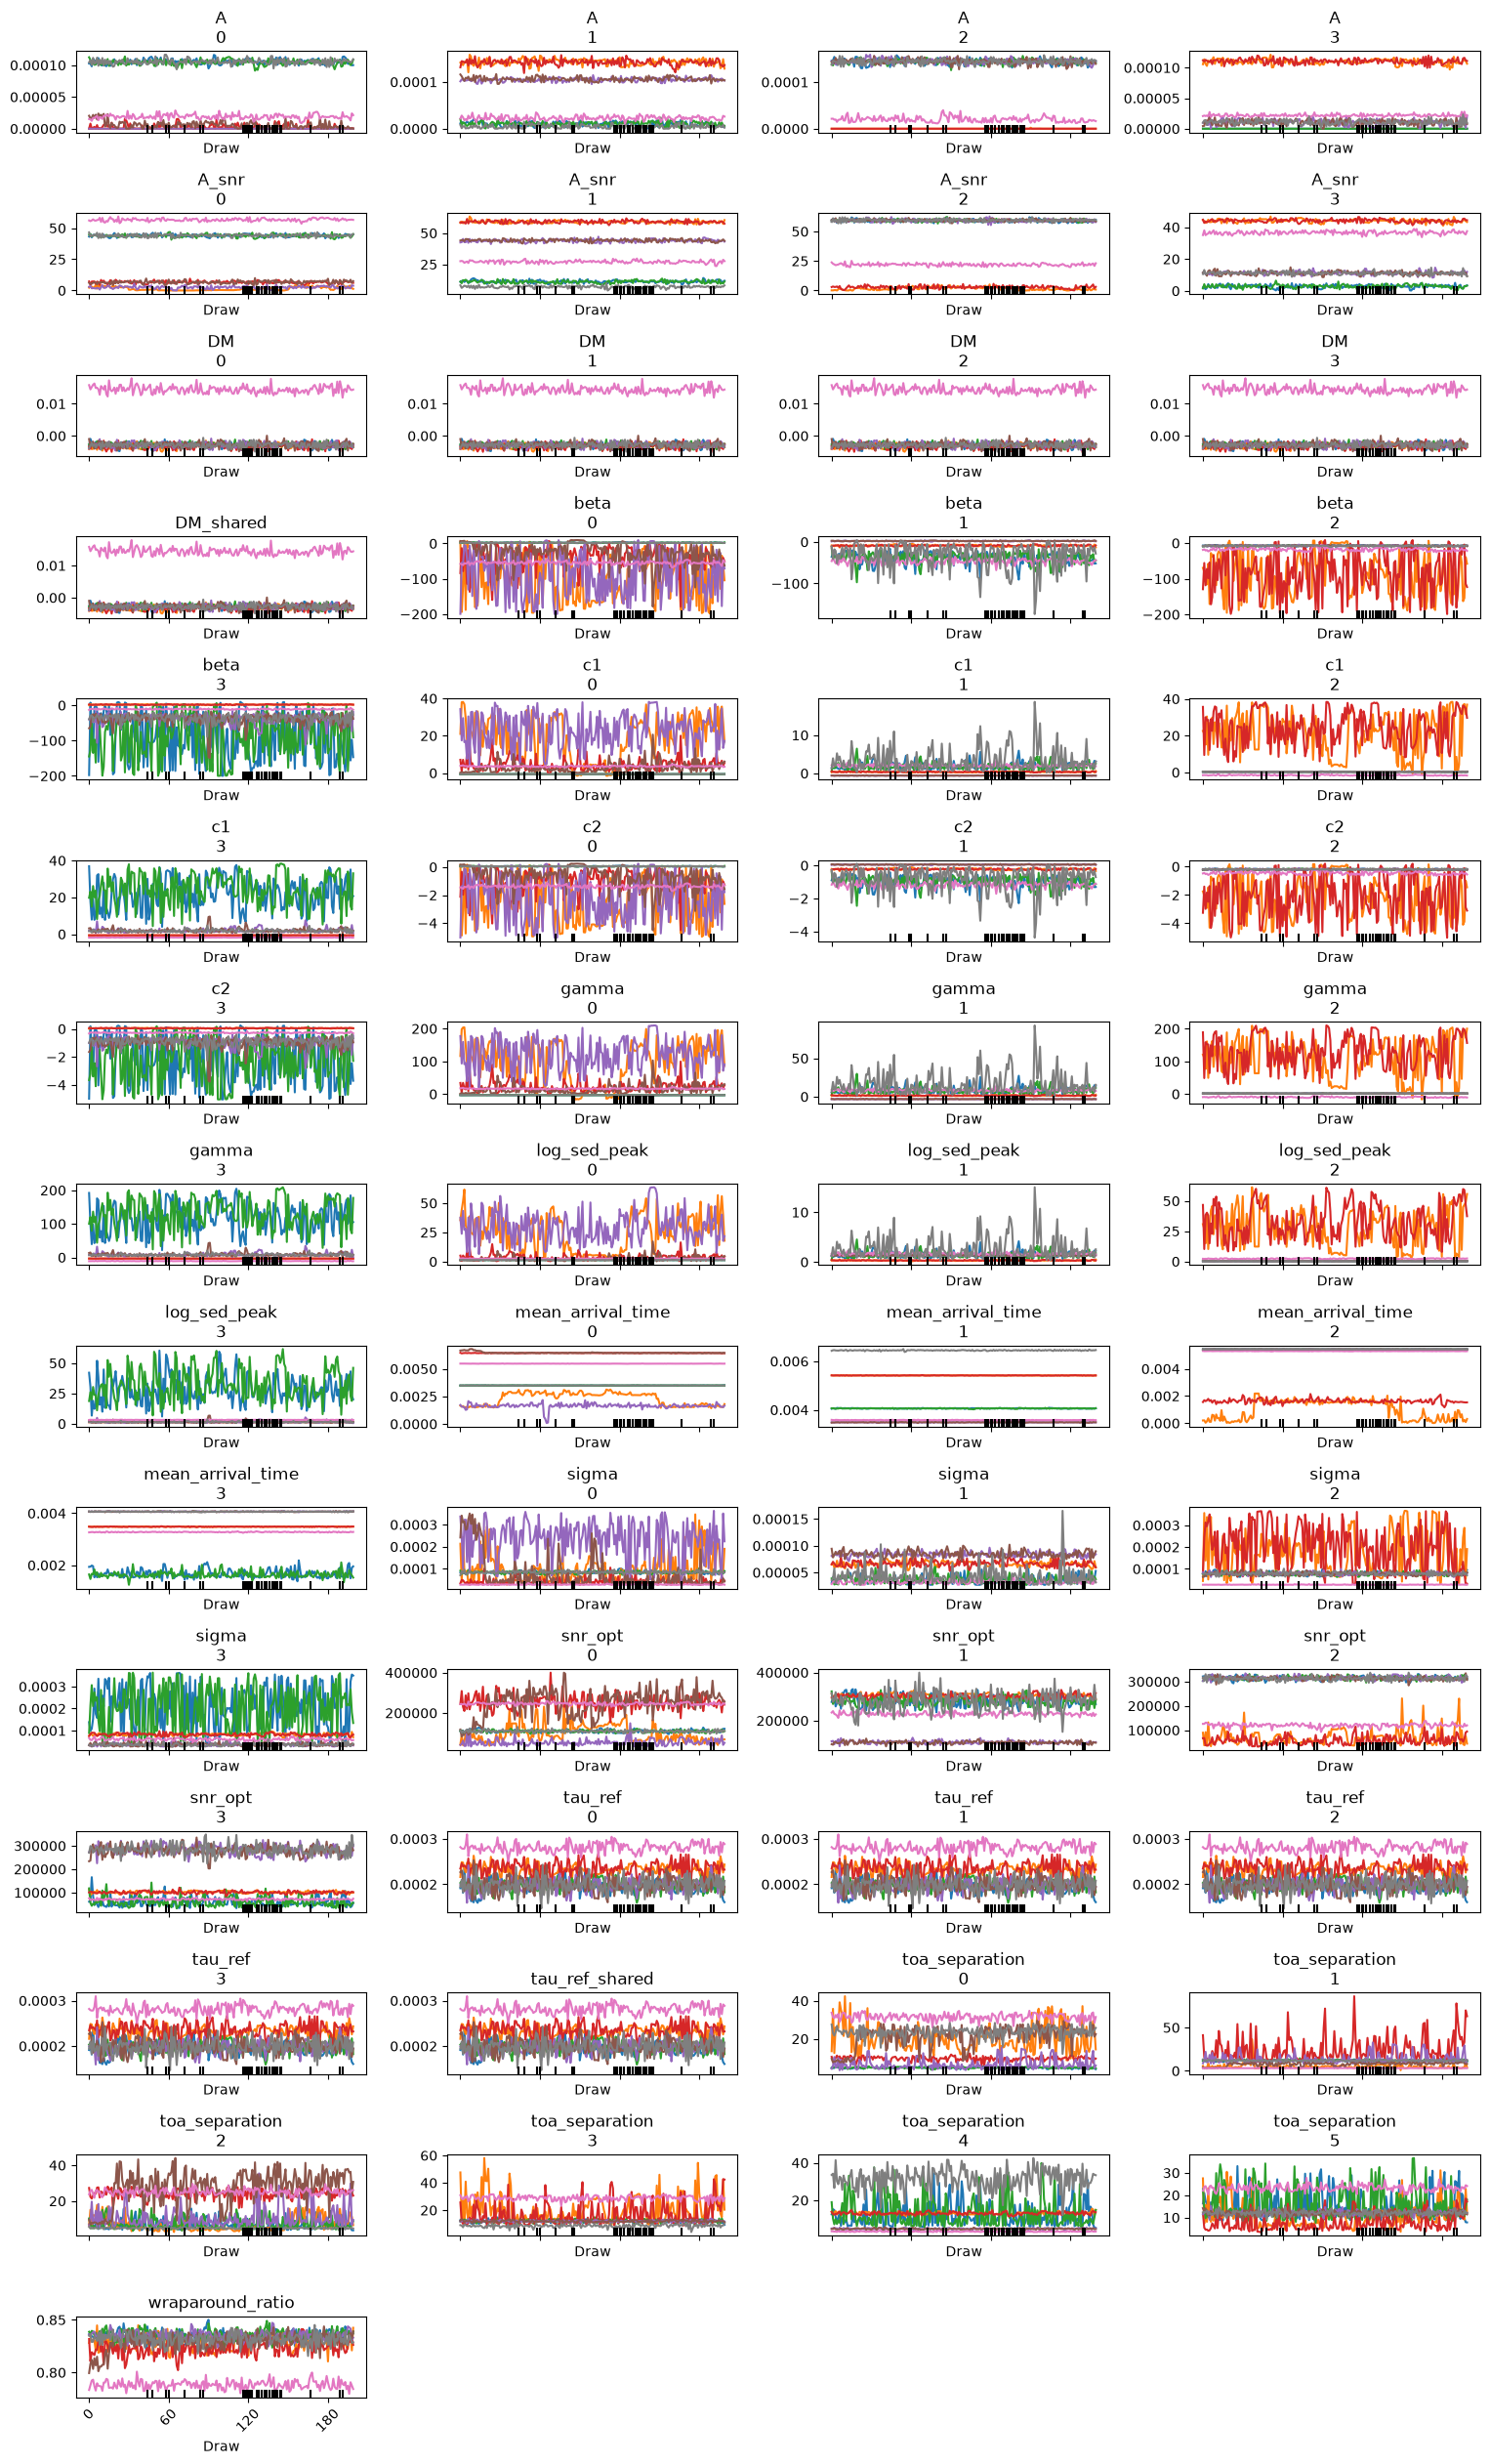

In [10]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="Explicitly requested dtype.*is not available",
    category=UserWarning,
)

azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [11]:
pe = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
active = s["A_snr"] > 3.0
for c in range(pe.shape[0]):
    t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)
    print(f"chain {c}: -log post {pe[c].mean():9.1f} ± {pe[c].std():4.1f}   "
          f"active {active[c].sum(-1).mean():.1f}   t [ms] {np.round(np.sort(t) * 1e3, 2)}   "
          f"A_snr {np.round(np.median(s['A_snr'][c], axis=0), 1)}")

chain 0: -log post    3772.2 ±  3.4   active 3.4   t [ms] [1.62 3.49 4.06 5.43]   A_snr [44.  11.2 59.2  2.9]
chain 1: -log post    3832.6 ±  4.3   active 2.3   t [ms] [1.55 1.57 3.48 5.42]   A_snr [ 0.9 58.7  1.4 44.1]
chain 2: -log post    3772.0 ±  3.5   active 3.5   t [ms] [1.6  3.49 4.06 5.43]   A_snr [44.  11.1 59.3  2.9]
chain 3: -log post    3808.2 ±  3.3   active 3.4   t [ms] [1.61 3.48 5.42 6.44]   A_snr [ 6.7 58.9  2.8 44. ]
chain 4: -log post    3772.2 ±  3.6   active 3.3   t [ms] [1.61 3.49 4.06 5.43]   A_snr [ 2.6 43.9 59.2 11.2]
chain 5: -log post    3754.3 ±  3.7   active 4.0   t [ms] [3.49 4.06 5.43 6.45]   A_snr [ 6.8 44.2 59.5 11. ]
chain 6: -log post    3551.6 ±  2.9   active 4.0   t [ms] [3.28 3.58 5.3  5.47]   A_snr [56.6 27.1 21.9 36.6]
chain 7: -log post    3753.1 ±  3.6   active 4.0   t [ms] [3.49 4.06 5.43 6.45]   A_snr [44.1  7.  59.5 11.2]


  from chain 6
Plotting for Posterior Draw #1347, 4 pulse(s)
A_snr [56.577377 27.092205 20.91988  35.954857]


/tmp/ipykernel_3627906/303027263.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


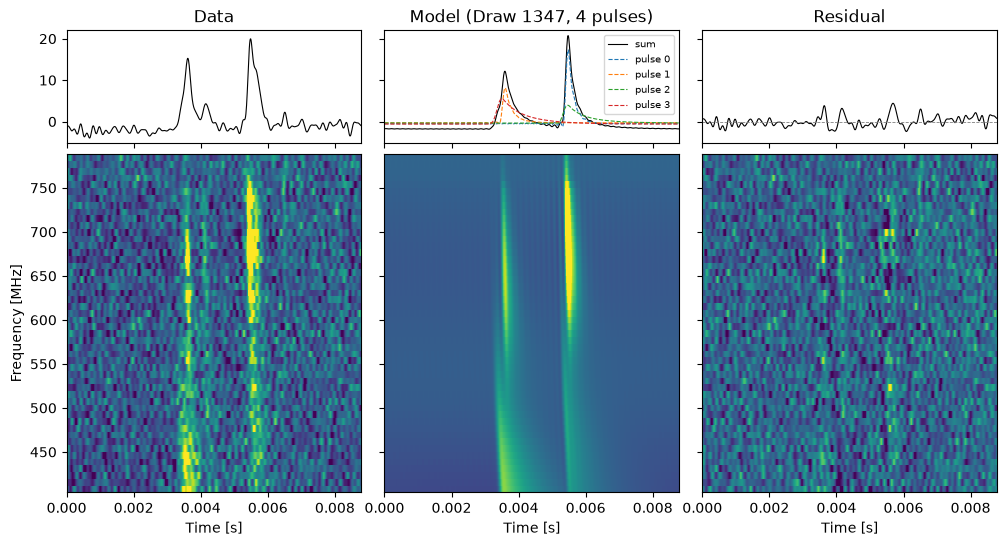

In [18]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = dict(mcmc.get_samples())
# For a marginalized fit, the fluences are not sampled: add the post-hoc draws first, flattened
# to (draws, n_pulses) to match get_samples(), e.g.
#     samples["A"] = extra["A"].reshape(-1, extra["A"].shape[-1])
if "A" not in samples:
    raise KeyError("samples has no 'A'. For a marginalized fit, add the fluences drawn by "
                   "posthoc_samples first (see the comment above).")

num_draws = len(next(iter(samples.values())))
n_pulses = samples["mean_arrival_time"].shape[-1]

# Pick a draw index using JAX random
# key = jax.random.PRNGKey(110)
key = jax.random.PRNGKey(56)

keep_chains = [6]                                        # the chains to draw from
n_per_chain = num_draws // mcmc.num_chains
allowed = np.concatenate([np.arange(c * n_per_chain, (c + 1) * n_per_chain) for c in keep_chains])
draw_idx = int(allowed[jax.random.randint(key, shape=(), minval=0, maxval=len(allowed))])

# Parameters of the chosen draw, each an array of shape (n_pulses,). Only the parameters the
# model reads are taken; 'A' is the fluence, which single_pulse_fn applies itself.
param_names = [k for k in ("mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2",
                           "gamma", "beta", "delta", "A", "A_snr") if k in samples]
test_params = {k: jnp.asarray(samples[k][draw_idx]).reshape(n_pulses) for k in param_names}

print(f"  from chain {draw_idx // n_per_chain}")
print(f"Plotting for Posterior Draw #{draw_idx}, {n_pulses} pulse(s)")
print("A_snr",test_params["A_snr"])

# Evaluate every pulse (vmap over the pulse axis), then sum them for the full model
M_FD_pulses = jax.vmap(single_pulse_fn)(test_params)       # (n_pulses, nfreq, nfourier)
M_FD = jnp.sum(M_FD_pulses, axis=0)                        # (nfreq, nfourier)

# The data and model live on the retained Fourier bins only, so each bin is put back at its own
# index on the full rfft grid before inverting; irfft on the truncated array would reinterpret
# bin k as frequency k / (Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt = burst.dt
n_full = Nseg // 2 + 1
bin_index = jnp.rint(jnp.asarray(burst.fourier_freqs).reshape(-1) * Nseg * dt).astype(int)
pad = lambda X: jnp.zeros(X.shape[:-1] + (n_full,), X.dtype).at[..., bin_index].set(X)

to_TD = lambda X: (1.0 / dt) * jnp.fft.irfft(pad(X), n=Nseg, axis=-1)
M_TD = to_TD(M_FD)
M_TD_pulses = to_TD(M_FD_pulses)                           # (n_pulses, nfreq, ntime)
data_TD = to_TD(burst.data_fd)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
pulse_ts = jnp.nansum(M_TD_pulses, axis=1)                 # (n_pulses, ntime)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8, label="sum")
if n_pulses > 1:
    # Each component separately, and its arrival time (at the reference frequency)
    colors = plt.cm.tab10(np.arange(n_pulses) % 10)
    t0 = np.asarray(test_params["mean_arrival_time"])
    for j in range(n_pulses):
        ax_ts_model.plot(time_plot, pulse_ts[j], color=colors[j], lw=0.8, ls="--", label=f"pulse {j}")
        # for ax in (ax_ts_model, ax_wf_model):
        #     ax.axvline(t0[j], color=colors[j], lw=0.6, alpha=0.6)
    ax_ts_model.legend(fontsize=7, loc="upper right")
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx}, {n_pulses} pulse{'s' if n_pulses > 1 else ''})")
ax_ts_resid.set_title("Residual")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 8.283221
Max Model abs: 7.512398
whitened residual sd: 1.187  (expect 1)


/tmp/ipykernel_2295843/3866287201.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


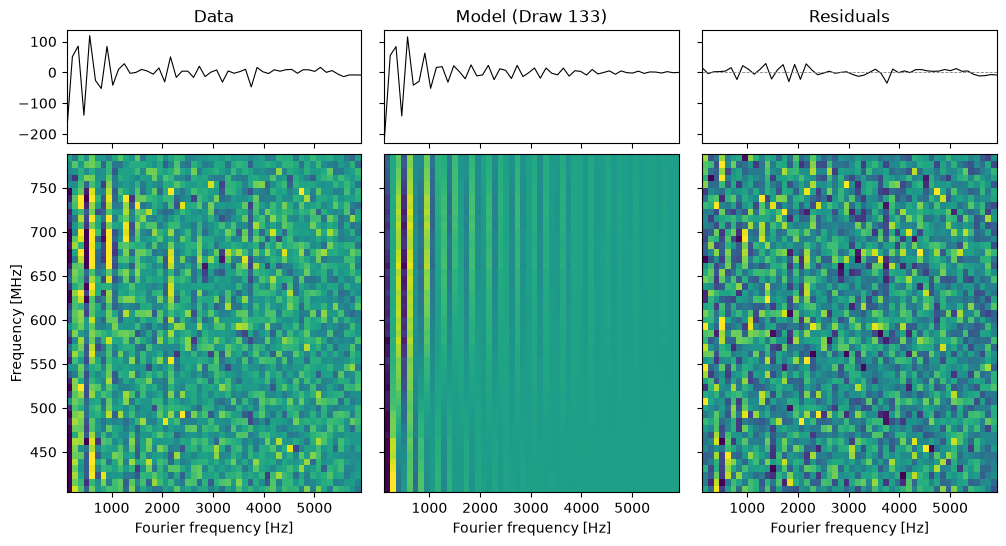

In [13]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
# test_params comes from the posterior-draw cell: each entry has shape (n_pulses,). Every pulse
# is evaluated (vmap over the pulse axis) and the pulses are summed into the full model.
M_FD = jnp.sum(jax.vmap(single_pulse_fn)(test_params), axis=0)     # (nfreq, nfourier)

# The data and the model already live on the truncated Fourier axis, which is exactly the set
# of bins the likelihood uses, so nothing needs slicing here.
data_reshaped_FFT = burst.data_fd
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

806 good channels -> 806 blocks of 1 (0 dropped); block span median 0.000 MHz, max 0.000 MHz
noise estimated from 171 of 858 time bins (first 20% of the segment)
Fourier truncation: keeping 429 of 430 bins (up to 48.8 kHz of 48.8 kHz)
weighted mean frequency 584.6 MHz, reference frequency 554.0 MHz
Max Data abs : 5.9051223
Max Model abs: 1.2720777
whitened residual sd: 1.082  (expect 1)


/tmp/ipykernel_3627906/3585239692.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


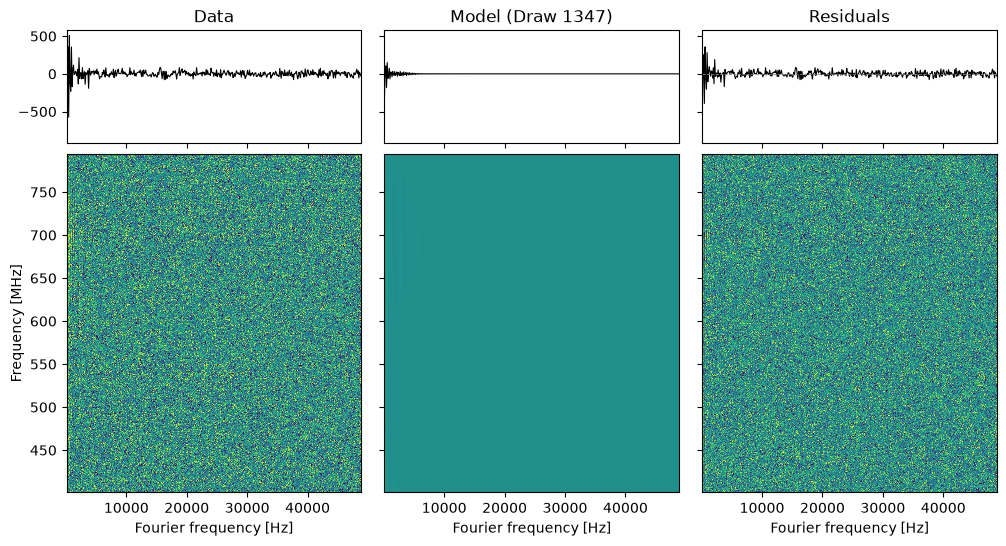

In [22]:
from dataclasses import asdict
from model import setup_model, running_power_law_log_sed

burst_raw = prepare_burst(path=data_path, n_avg=1, fd_downsample=1, toa=None,
                          noise_fraction=0.2, verbose=True)

# Same model constants, except the channel width, which changes with channel averaging
constants_raw = asdict(single_pulse_fn.constants)
constants_raw["channel_width"] = jnp.asarray(burst_raw.channel_width).reshape(-1, 1)

# SED in gamma, beta: c1 and c2 are tied to the downsampled burst's spectral basis, gamma and beta are not
single_pulse_fn_raw = setup_model(constants_raw, burst_raw.freq_channels, burst_raw.times,
                                  sed_fn=running_power_law_log_sed,
                                  fourier_freqs=burst_raw.fourier_freqs,
                                  _wraparoundFDdiagnostic=False)

params_raw = {k: v for k, v in test_params.items() if k not in ("c1", "c2")}
M_FD = jnp.sum(jax.vmap(single_pulse_fn_raw)(params_raw), axis=0)     # (nfreq_raw, nfourier_raw)

data_reshaped_FFT = burst_raw.data_fd

sigma_bins = jnp.broadcast_to(burst_raw.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst_raw.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst_raw.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()